# Explorer les prix des carburants de 2007 à 2026
Les données proviennent exclusivement des archives officielles de prix-carburants.gouv.fr.
L'année 2026 est partielle. Chaque ligne de prix représente une déclaration.
Les champs géographiques décrivent la station telle qu'elle apparaît dans l'archive annuelle.

Les prix de 2007 à 2021 sont divisés par 1 000. À partir de 2022, ils sont conservés en euros.
Les dates sont préservées sans fuseau ajouté, car les fichiers XML n'en indiquent pas.
Les valeurs invalides sont comptées dans les bilans. Les prix inférieurs à 0,20 €/L ou supérieurs
à 5 €/L sont conservés et signalés par suspect_price. Ce seuil exploratoire est modifiable dans
le script de préparation. Les archives originales permettent de revenir aux données sources.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data/processed/annual").exists():
    raise FileNotFoundError("Ouvre ce notebook depuis la racine de Fuel_analyser.")
ANNUAL = ROOT / "data/processed/annual"


## Couverture et qualité par année

In [2]:
reports = [
    json.loads(path.read_text(encoding="utf-8"))
    for path in sorted(ANNUAL.glob("*/quality.json"))
]
quality = pd.DataFrame(reports).set_index("year")
display(quality[[
    "station_count", "retained_rows", "invalid_rows",
    "exact_duplicates_removed", "suspect_price_rows",
    "conflicting_timestamp_rows", "outside_archive_year_rows",
]])


,station_count,retained_rows,invalid_rows,exact_duplicates_removed,suspect_price_rows,conflicting_timestamp_rows,outside_archive_year_rows
year,,,,,,,
2007,7904,866445,548,0,160,4,0
2008,8394,1421554,605,0,50,6,0
2009,9387,1397067,1229,0,70,192,0
2010,10130,1443536,1718,0,41,0,0
2011,10001,1611812,1338,0,33,2,0
2012,10256,1903238,1229,0,30,2,0
2013,10807,2150589,1415,0,27,312,0
2014,11064,2197948,1326,0,0,14,0
2015,12333,3302099,2601,3160,1,2570,0


## Choisir une année et un carburant
Tous les carburants sont chargés par défaut. Pour filtrer, remplace Tous par Gazole, SP95, SP98, E10, E85 ou GPLc. Change les paramètres puis réexécute les cellules suivantes.

In [3]:
YEAR = 2022
FUEL = "Tous"

folder = ANNUAL / str(YEAR)
filters = None if FUEL == "Tous" else [("fuel", "==", FUEL)]
prices = pd.read_parquet(folder / "prices.parquet", filters=filters)
stations = pd.read_parquet(folder / "stations.parquet")
interruptions = pd.read_parquet(folder / "interruptions.parquet")
display(prices.head())
display(prices.groupby("fuel")["price_eur_l"].agg(nombre="count", minimum="min", mediane="median", maximum="max"))
print(f"{len(prices):,} déclarations de prix pour {FUEL} en {YEAR}.")


,station_id,fuel,price_reported_at,price_eur_l,suspect_price,outside_archive_year
0,1000001,Gazole,2022-01-03 08:44:18,1.572,False,False
1,1000001,Gazole,2022-01-05 10:08:11,1.560,False,False
2,1000001,Gazole,2022-01-10 10:09:08,1.603,False,False
3,1000001,Gazole,2022-01-17 12:34:42,1.616,False,False
4,1000001,Gazole,2022-01-17 12:34:44,1.616,False,False


,nombre,minimum,mediane,maximum
fuel,,,,
E10,1247056,0.001,1.769,9.999
E85,430263,0.001,0.809,9.969
GPLc,206917,0.019,0.864,7.000
Gazole,1548593,0.001,1.862,9.999
SP95,377007,0.004,1.805,9.999
SP98,1234760,0.001,1.874,9.999


5,044,596 déclarations de prix pour Tous en 2022.


## Examiner les données avant l'analyse

In [4]:
display(prices.dtypes)
display(prices.isna().sum().rename("Valeurs manquantes"))
display(prices["price_eur_l"].describe())
display(prices.loc[prices["suspect_price"]].head(10))
conflicts = prices.duplicated(["station_id", "fuel", "price_reported_at"], keep=False)
print(f"{conflicts.sum():,} lignes présentent plusieurs prix au même instant pour une station.")


station_id                      object
fuel                            object
price_reported_at       datetime64[us]
price_eur_l                    float64
suspect_price                     bool
outside_archive_year              bool
dtype: object

station_id              0
fuel                    0
price_reported_at       0
price_eur_l             0
suspect_price           0
outside_archive_year    0
Name: Valeurs manquantes, dtype: int64

count    5.044596e+06
mean     1.722076e+00
std      3.837600e-01
min      1.000000e-03
25%      1.659000e+00
50%      1.806000e+00
75%      1.951000e+00
max      9.999000e+00
Name: price_eur_l, dtype: float64

,station_id,fuel,price_reported_at,price_eur_l,suspect_price,outside_archive_year
49250,1750001,SP95,2022-03-05 18:59:00,9.936,True,False
50675,1960005,Gazole,2022-10-06 08:03:56,7.762,True,False
53146,1980001,Gazole,2022-11-30 18:53:06,7.765,True,False
54615,2000005,Gazole,2022-10-11 11:42:51,9.999,True,False
73205,2200014,E85,2022-06-13 15:47:07,0.085,True,False
78047,2280001,E10,2022-04-20 11:16:15,7.725,True,False
89805,2600006,SP95,2022-05-31 17:23:54,0.004,True,False
96157,3000004,Gazole,2022-07-13 20:31:52,0.056,True,False
141300,4300001,Gazole,2022-07-12 09:30:00,5.059,True,False
147595,5000001,E10,2022-02-19 08:56:23,7.779,True,False


749 lignes présentent plusieurs prix au même instant pour une station.


## Observer une station
Le tracé montre les prix déclarés d'une station sur l'année choisie. Lorsque tous les carburants sont chargés, cet exemple graphique utilise le gazole. Le tableau précédent présente les six carburants disponibles.
Les observations atypiques et les instants où plusieurs prix différents sont déclarés
sont écartés de cet exemple graphique. Les interruptions sont affichées pour examen séparé.
Une absence de nouvelle déclaration ne renseigne pas à elle seule la disponibilité.

Pour une courbe nationale, il faudra reconstruire les prix valides par station à des dates
communes, intégrer les interruptions et choisir une règle de fraîcheur. La moyenne directe
des déclarations donnerait plus de poids aux stations qui modifient souvent leurs prix.


,station_id,postal_code,city,address,road_type,latitude,longitude
13635,95800003,95800,Cergy,Boulevard d'Osny,R,49.05,2.045


,station_id,kind,fuel,type,start_raw,end_raw
208655,95800003,rupture,SP95,None,2009-12-16T12:07:00,
208656,95800003,rupture,E10,None,2022-10-24T11:04:19,2022-10-24T17:51:01
208657,95800003,rupture,E10,None,2022-11-04T10:40:04,2022-11-04T17:04:58
208658,95800003,rupture,SP98,None,2022-11-01T10:18:24,2022-11-02T10:32:46
208659,95800003,rupture,SP98,None,2022-11-04T10:40:05,2022-11-04T17:04:58
208660,95800003,rupture,E10,None,2022-11-03T12:18:36,2022-11-03T17:05:49
208661,95800003,rupture,SP98,None,2022-10-14T17:14:38,2022-10-20T12:12:53
208662,95800003,rupture,SP98,None,2022-10-21T10:23:46,2022-10-21T17:26:02
208663,95800003,rupture,SP98,None,2022-10-24T11:04:19,2022-10-25T17:24:20
208664,95800003,rupture,E10,None,2022-10-14T17:14:38,2022-10-20T12:12:53


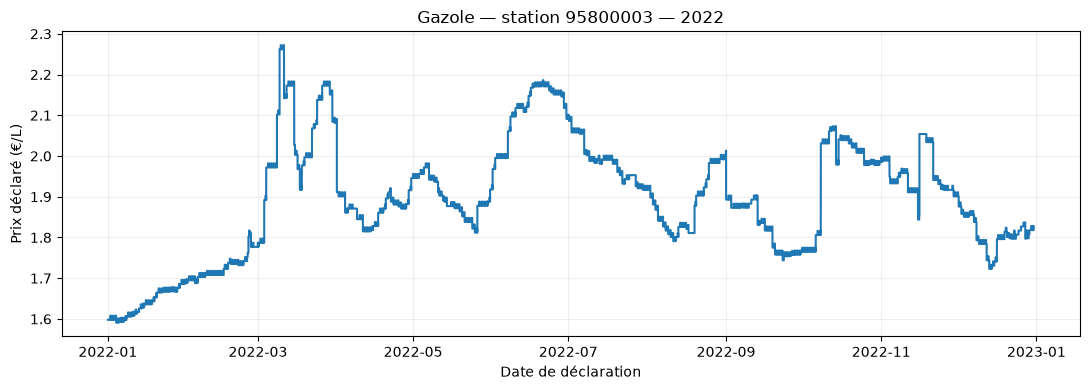

In [5]:
usable = prices.loc[
    ~prices["suspect_price"] & ~prices["outside_archive_year"] & ~conflicts
].copy()
graph_fuel = "Gazole" if FUEL == "Tous" else FUEL
usable = usable.loc[usable["fuel"].eq(graph_fuel)]
station_id = usable["station_id"].value_counts().index[0]
station_prices = usable.loc[usable["station_id"].eq(station_id)].sort_values("price_reported_at")
display(stations.loc[stations["station_id"].eq(station_id)])
display(interruptions.loc[interruptions["station_id"].eq(station_id)].head(20))

fig, ax = plt.subplots(figsize=(11, 4))
ax.step(station_prices["price_reported_at"], station_prices["price_eur_l"], where="post")
ax.set(title=f"{graph_fuel} — station {station_id} — {YEAR}", xlabel="Date de déclaration", ylabel="Prix déclaré (€/L)")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


## Tes questions d'analyse
- Quelles années présentent le plus de données manquantes ou atypiques ?
- Comment le nombre de stations suivies évolue-t-il ?
- Observe-t-on des hausses ou baisses rapides pour la station choisie ?
- Les interruptions enregistrées coïncident-elles avec ces périodes ?

Les données de prix permettent de décrire les évolutions observées.
L'attribution à une cause politique ou économique demandera une méthode et des éléments
de contexte documentés.
